In [1]:
from sklearn.metrics.pairwise import cosine_similarity
import scipy.stats as st

A = [5, 4, 4, 5, 5]
B = [2, 1, 1, 2, 2]
print("Pearson", st.pearsonr(A, B))
print("Cosine", cosine_similarity([A], [B]))

Pearson PearsonRResult(statistic=np.float64(0.9999999999999999), pvalue=np.float64(0.0))
Cosine [[0.98181054]]


In [2]:
A = [5, 4, 4, 5, 5]
B = [1, 2, 2, 1, 1]
print("Pearson", st.pearsonr(A, B))
print("Cosine", cosine_similarity([A], [B]))

Pearson PearsonRResult(statistic=np.float64(-0.9999999999999999), pvalue=np.float64(0.0))
Cosine [[0.90359426]]


In [3]:
import numpy as np

A = np.array([5, 4, 4, 5, 5]) * 10
B = np.array([2, 1, 1, 2, 2]) * -10
print("Pearson", st.pearsonr(A, B))
print("Cosine", cosine_similarity([A], [B]))

Pearson PearsonRResult(statistic=np.float64(-0.9999999999999998), pvalue=np.float64(3.971862410081708e-24))
Cosine [[-0.98181054]]


In [4]:
import pandas as pd

links = pd.read_csv("../resources/ml-latest-small/links.csv")
tags = pd.read_csv("../resources/ml-latest-small/tags.csv")
movies = pd.read_csv("../resources/ml-latest-small/movies.csv")
ratings = pd.read_csv("../resources/ml-latest-small/ratings.csv")


In [5]:
ratings

,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931
...,...,...,...,...
100831,610,166534,4.0,1493848402
100832,610,168248,5.0,1493850091
100833,610,168250,5.0,1494273047
100834,610,168252,5.0,1493846352


In [6]:
movies

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy
...,...,...,...
9737,193581,Black Butler: Book of the Atlantic (2017),Action|Animation|Comedy|Fantasy
9738,193583,No Game No Life: Zero (2017),Animation|Comedy|Fantasy
9739,193585,Flint (2017),Drama
9740,193587,Bungo Stray Dogs: Dead Apple (2018),Action|Animation


In [7]:
tags

,userId,movieId,tag,timestamp
0,2,60756,funny,1445714994
1,2,60756,Highly quotable,1445714996
2,2,60756,will ferrell,1445714992
3,2,89774,Boxing story,1445715207
4,2,89774,MMA,1445715200
...,...,...,...,...
3678,606,7382,for katie,1171234019
3679,606,7936,austere,1173392334
3680,610,3265,gun fu,1493843984
3681,610,3265,heroic bloodshed,1493843978


In [8]:
links

,movieId,imdbId,tmdbId
0,1,114709,862.0
1,2,113497,8844.0
2,3,113228,15602.0
3,4,114885,31357.0
4,5,113041,11862.0
...,...,...,...
9737,193581,5476944,432131.0
9738,193583,5914996,445030.0
9739,193585,6397426,479308.0
9740,193587,8391976,483455.0


In [9]:
from sklearn.model_selection import train_test_split
import pandas as pd

train_parts = []
test_parts = []

for user_id, user_ratings in ratings.groupby("userId"):
    train, test = train_test_split(
        user_ratings,
        test_size=0.3,
        random_state=42
    )

    train_parts.append(train)
    test_parts.append(test)

train_ratings = pd.concat(train_parts).reset_index(drop=True)
test_ratings = pd.concat(test_parts).reset_index(drop=True)

print(len(train_ratings))
print(len(test_ratings))

70316
30520


In [10]:
import src.content_based as cb
from importlib import reload
reload(cb)

cbr = cb.ContentBasedRec()

cbr.train(movies_data=movies, ratings=train_ratings)

/home/taras-hamkalo/repositories/code/ddw/hamkatar/06/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/taras-hamkalo/repositories/code/ddw/hamkatar/06/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:180: UserWarning: CUDA initialization: Unexpected error from cudaGetDeviceCount(). Did you run some cuda functions before calling NumCudaDevices() that might have already set an error? Error 804: forward compatibility was attempted on non supported HW (Triggered internally at /pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return torch._C._cuda_getDeviceCount() > 0
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 14910.38it/s]


In [11]:
user_id = 1
relevance_threshold = 3.5
top_k = 1000

user_test = test_ratings[
    test_ratings["userId"] == user_id
    ]

relevant_movies = set(
    user_test[
        user_test["rating"] >= relevance_threshold
        ]["movieId"]
)

print(relevant_movies)

{1920, 2048, 260, 2692, 2054, 1031, 2058, 1805, 661, 3479, 2329, 923, 157, 2078, 543, 3744, 163, 2596, 2470, 4006, 552, 1196, 1197, 2991, 1073, 2997, 2872, 441, 1210, 2366, 1214, 1473, 1732, 2502, 1224, 457, 2761, 333, 3450, 2000, 2899, 1620, 2005, 2648, 3034, 2139, 2012, 349, 2268, 2395, 2018, 2406, 1127, 1256, 3052, 3053, 1136, 1265, 1777, 2291, 3578, 1275}


In [12]:
recommendations = cbr.recommend(user_id, top_k=top_k)

recommended_movies = set(
    recommendations["movieId"]
)

print(recommended_movies)

{2048, 116738, 2052, 2053, 2054, 143365, 2059, 6156, 69644, 45074, 122898, 4115, 47124, 122902, 4121, 96281, 27, 122906, 75805, 4126, 4123, 4128, 8225, 2073, 4133, 4135, 6185, 77866, 6188, 44, 4142, 8241, 2100, 51255, 2106, 116797, 26686, 4158, 4161, 2117, 4167, 26696, 6215, 30793, 57421, 4174, 2130, 2133, 86, 2134, 69720, 2139, 73822, 2144, 133217, 92259, 2148, 4197, 6249, 114795, 67695, 69746, 118900, 4214, 6263, 6264, 49272, 49278, 2177, 4232, 4233, 4239, 108689, 4242, 2194, 148, 149, 67734, 2195, 45208, 6297, 110746, 47254, 153, 116897, 163, 112804, 6308, 166, 6310, 26792, 157865, 8363, 175, 8368, 4273, 100527, 4275, 4276, 186, 98491, 57536, 4293, 6341, 53447, 2248, 106696, 65738, 2252, 116941, 2253, 4306, 2260, 2261, 2262, 51412, 2264, 2265, 78041, 217, 53468, 172253, 59615, 2271, 151781, 2279, 141544, 6377, 233, 8427, 26861, 2288, 4340, 2294, 4342, 4343, 252, 80126, 256, 112897, 4355, 100611, 92420, 260, 135436, 94478, 2320, 279, 47384, 6424, 4378, 2328, 86298, 285, 2333, 135456,

In [13]:
recommendations.head(20)


,movieId,title,genres,score
3069,4121,Innerspace (1987),Action|Adventure|Comedy|Sci-Fi,0.714012
4586,6812,"Rookie, The (1990)",Action|Comedy|Thriller,0.713945
4717,7036,Teen Wolf (1985),Comedy|Fantasy,0.711641
6580,55247,Into the Wild (2007),Action|Adventure|Drama,0.710052
5847,32554,Memories (Memorîzu) (1995),Animation|Fantasy|Sci-Fi|Thriller,0.709466
4005,5657,Flashback (1990),Action|Adventure|Comedy|Crime|Drama,0.706085
2827,3784,"Kid, The (2000)",Comedy|Fantasy,0.703380
4488,6636,"Sure Thing, The (1985)",Comedy|Romance,0.701809
147,175,Kids (1995),Drama,0.699824
6274,47538,Crime Busters (1977),Action|Adventure|Comedy|Crime,0.695270


In [18]:
hits = recommended_movies.intersection(relevant_movies)

print(len(hits), hits)

17 {2048, 163, 2596, 260, 2054, 2470, 2502, 2761, 2406, 3052, 1197, 2000, 2005, 2872, 3578, 2139, 2012}


In [15]:
len(train_ratings[train_ratings["userId"] == user_id])

162

In [16]:
len(test_ratings[test_ratings["userId"] ==  user_id])

70

In [17]:
movies.copy()["genres"].fillna("").str.split("|")


0       [Adventure, Animation, Children, Comedy, Fantasy]
1                          [Adventure, Children, Fantasy]
2                                       [Comedy, Romance]
3                                [Comedy, Drama, Romance]
4                                                [Comedy]
                              ...                        
9737                 [Action, Animation, Comedy, Fantasy]
9738                         [Animation, Comedy, Fantasy]
9739                                              [Drama]
9740                                  [Action, Animation]
9741                                             [Comedy]
Name: genres, Length: 9742, dtype: object

# Evaluation

In [2]:
import pandas as pd

links = pd.read_csv("../resources/ml-latest-small/links.csv")
tags = pd.read_csv("../resources/ml-latest-small/tags.csv")
movies = pd.read_csv("../resources/ml-latest-small/movies.csv")
ratings = pd.read_csv("../resources/ml-latest-small/ratings.csv")

In [19]:
import src.content_based as cb
import src.evaluation as eval
from importlib import reload
reload(cb)
reload(eval)
# recall computation
# ---> 28 return relevant_retrieved / len(relevant)
# ZeroDivisionError: division by zero

cbr = cb.ContentBasedRec(rating_like_threshold=3.5)
res = eval.evaluate(
    recommender=cbr,
    movies_data=movies,
    ratings_data=ratings,
    relevance_threshold=3.5,
    test_size_per_user=0.3,
    seed=42
)

res

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 3990.15it/s]


KeyboardInterrupt: 

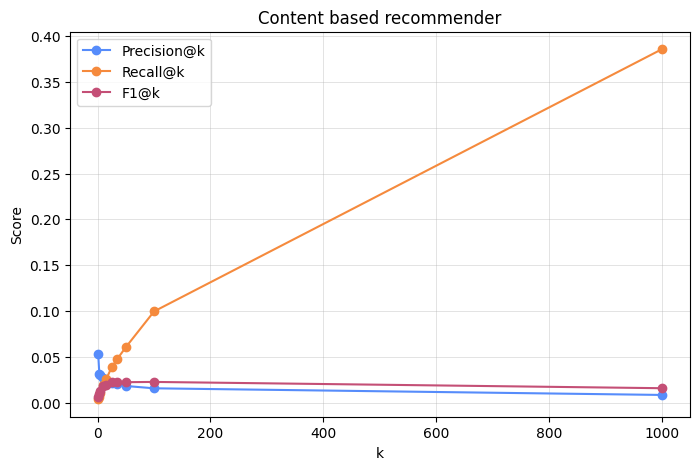

In [24]:
reload(eval)

eval.plot_results(results=res, title="Content based recommender")

In [ ]:
len(train_ratings[train_ratings["userId"] == 54])